In [1]:
from collections.abc import Sequence
from itertools import accumulate
from random import sample, seed, shuffle, randint
import matplotlib.pyplot as plt

In [2]:
class Child:
    _name: str
    _characteristics: tuple [bool, ...]

    def __init__(self, name: str, characteristics: Sequence[bool]):
        self._name = name
        self._characteristics = tuple(characteristics)

    def difference(self, other: "Child") -> int:
        return sum(s != o for s, o in zip(self._characteristics, other._characteristics))

    def __str__(self) -> str:
        return f"{self._name}: {''.join('+' if c else '-' for c in self._characteristics)}"

    def __repr__(self) -> str:
        return f"{self._name}"

    def __eq__(self, other) -> bool:
        return id(self) == id(other)

    def __lt__(self, other):
        return id(self) < id(other)

## Generate Initial Conditions

In [3]:
def generate_initial_condition(num_children: int, num_characteristics: int) -> list[Child]:
    children = list()

    for c in range(num_children):
        name = f"Child {c}"
        characteristics = sample([True, False], k=num_characteristics, counts=[num_characteristics, num_characteristics])
        children.append(Child(name, characteristics))

    return children

## Fitness

In [4]:
def fitness(sol: list[Child]) -> int:
    return sum(a.difference(b) for a, b in zip(sol, sol[1:] + sol[:1]))

## Swap Mutation

In [5]:
def swap_mutation(solution: list[Child]) -> list[Child]:
    i1, i2 = sample(range(len(solution)), k=2)
    new_solution = solution.copy()
    new_solution[i1:i2+1] = reversed(new_solution[i1:i2+1])
    return new_solution

## Insert Mutation

In [6]:
def insert_mutation(solution: list[Child]) -> list[Child]:
    i1, i2 = sample(range(len(solution)), k=2)
    new_solution = solution.copy()
    moved = new_solution.pop(i2)
    # after the pop, everything right of i2 shifts left by one
    pos = i1 + 1 if i1 < i2 else i1
    new_solution.insert(pos, moved)
    return new_solution


## Scrample Mutation

In [7]:
def scramble_mutation(solution: list[Child]) -> list[Child]:
    """Shuffle the children at k randomly chosen (not necessarily consecutive) loci."""
    n = len(solution)
    k = randint(3, n)
    loci = sample(range(n), k=k)
    values = [solution[i] for i in loci]
    shuffle(values)
    new_solution = solution.copy()
    for i, v in zip(loci, values):
        new_solution[i] = v
    return new_solution

## Run Algorithm

In [8]:
def run_sga(algorithm, children: list[Child], max_steps: int) -> tuple[list[Child], list[int]]:
    history = []
    current_sol = children
    current_fit = fitness(current_sol)
    history.append(current_fit)
    for steps in range(max_steps):
        # first_dif, second_dif = False, False
        # while not first_dif and not second_dif:
        new_sol = algorithm(current_sol)
            # first_dif, second_dif = check_neighbors(current_sol, new_sol, i1, i2)
        new_fit = fitness(new_sol)
        history.append(new_fit)
        if new_fit >= current_fit:
            current_sol = new_sol
            current_fit = new_fit
    return current_sol, history


## Initial Conditions # 1

In [9]:
num_children = 20
num_characteristics = 10
seed(42)
children = generate_initial_condition(num_children, num_characteristics)

## Swap Mutation Solution

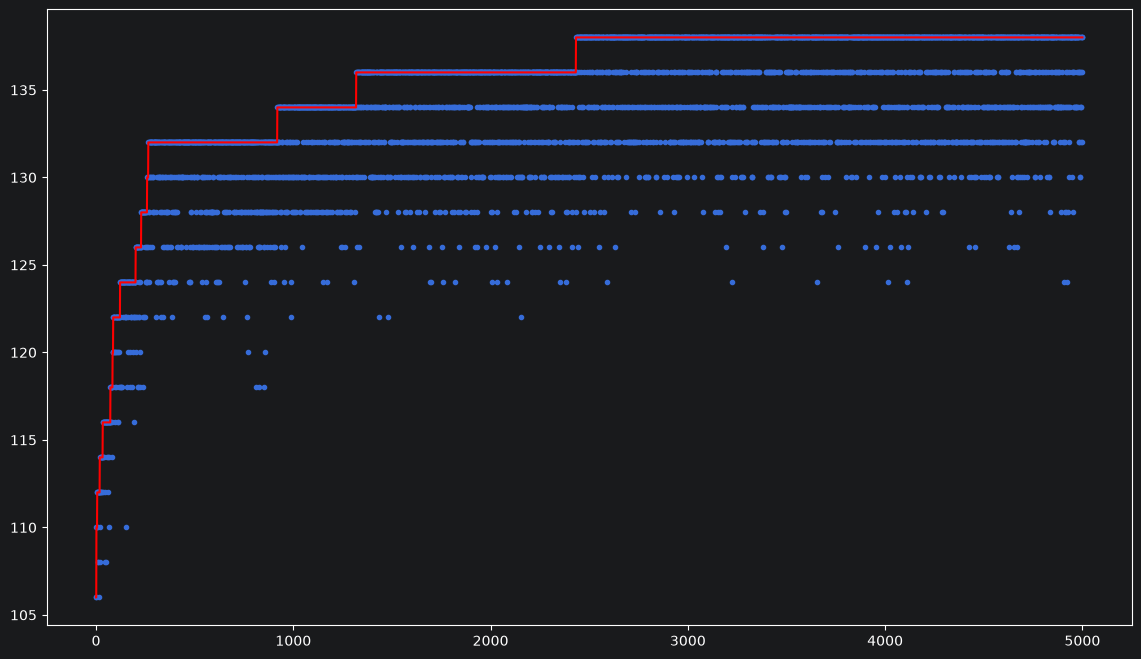

In [10]:
swap_solution, swap_history = run_sga(algorithm=swap_mutation, children=children, max_steps=5000)
plt.figure(figsize=(14, 8))
plt.plot(
    range(len(swap_history)),
    list(accumulate(swap_history, max)),
    color='red'
)
_ = plt.scatter(range(len(swap_history)), swap_history, marker='.')

## Insert Mutation Solution

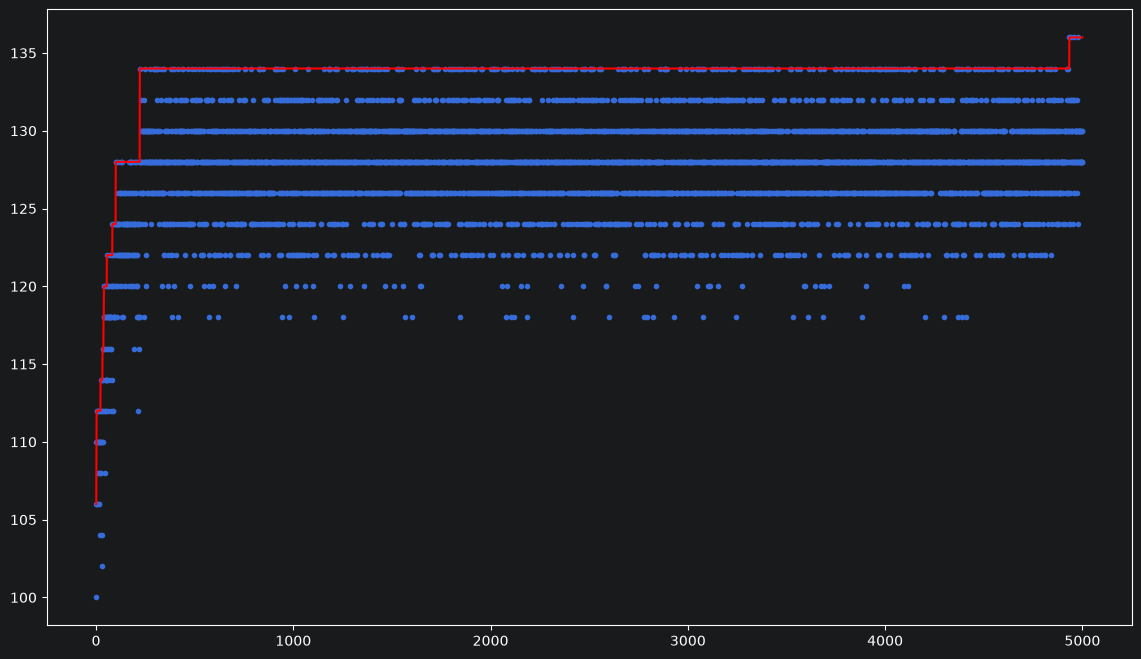

In [11]:
insert_solution, insert_history = run_sga(algorithm=insert_mutation, children=children, max_steps=5000)

plt.figure(figsize=(14, 8))
plt.plot(
    range(len(insert_history)),
    list(accumulate(insert_history, max)),
    color='red'
)
_ = plt.scatter(range(len(insert_history)), insert_history, marker='.')

## Scrample Mutation Solution

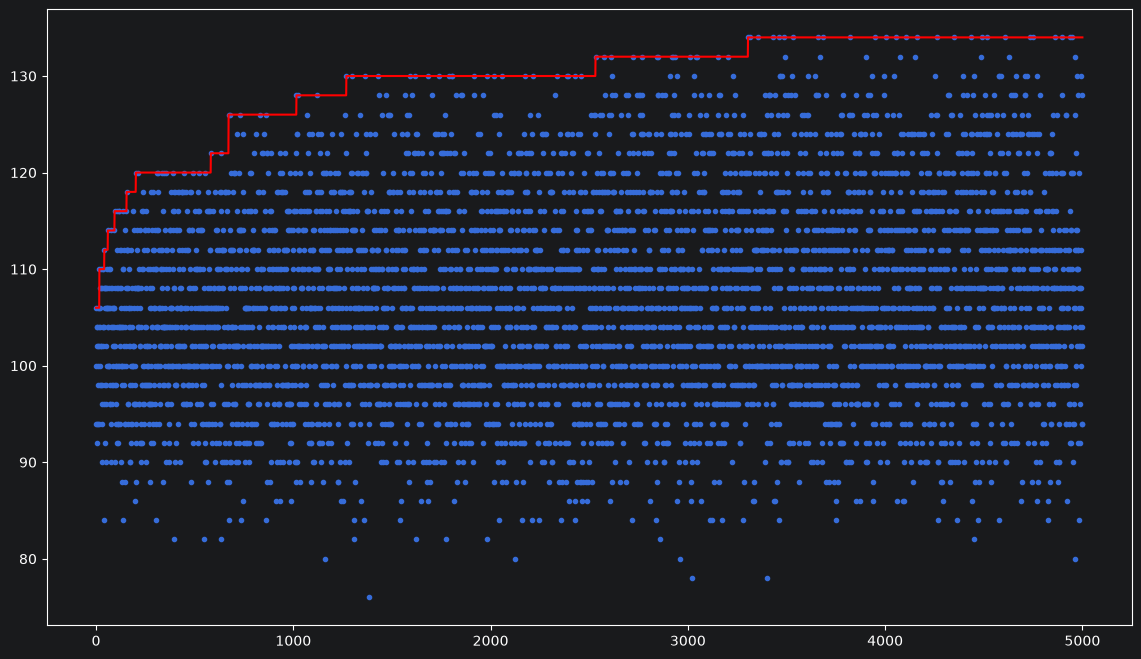

In [12]:
scramble_solution, scramble_history = run_sga(algorithm=scramble_mutation, children=children, max_steps=5000)

plt.figure(figsize=(14, 8))
plt.plot(
    range(len(scramble_history)),
    list(accumulate(scramble_history, max)),
    color='red'
)
_ = plt.scatter(range(len(scramble_history)), scramble_history, marker='.')

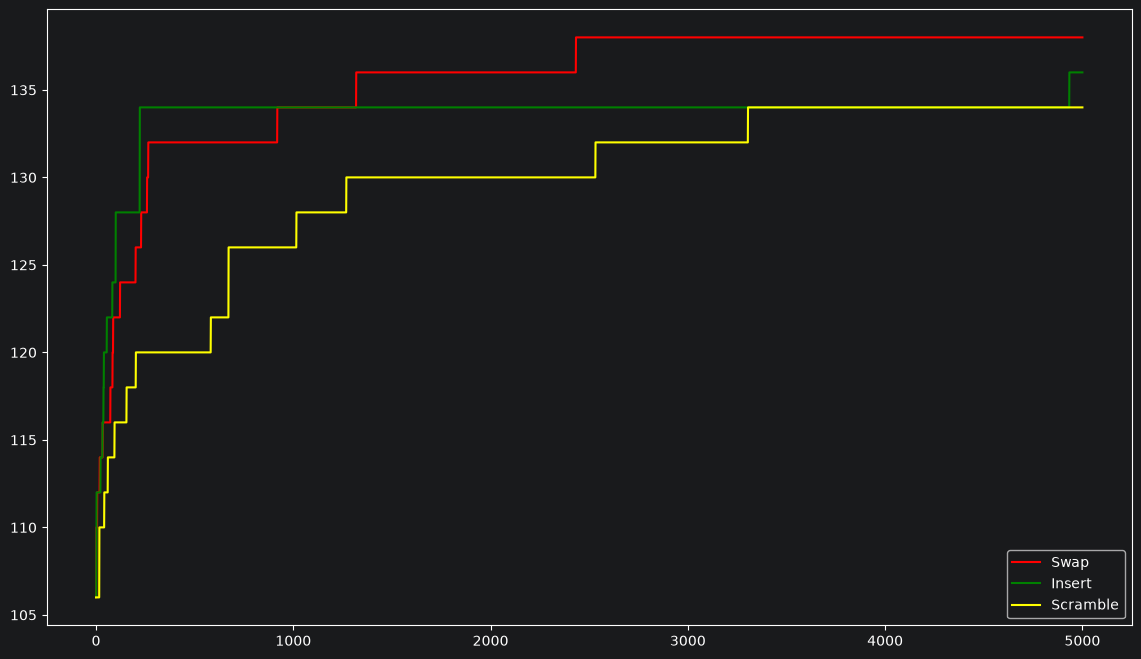

In [13]:
plt.figure(figsize=(14, 8))
plt.plot(
    range(len(swap_history)),
    list(accumulate(swap_history, max)),
    color='red'
)
plt.plot(
    range(len(insert_history)),
    list(accumulate(insert_history, max)),
    color='green'
)
plt.plot(
    range(len(scramble_history)),
    list(accumulate(scramble_history, max)),
    color='yellow'
)
plt.legend(["Swap", "Insert", "Scramble"], loc="lower right")

## Initial Conditions # 2

In [16]:
num_children = 50
num_characteristics = 20
seed(42)
children = generate_initial_condition(num_children, num_characteristics)
swap_solution, swap_history = run_sga(algorithm=swap_mutation, children=children, max_steps=100_000)
insert_solution, insert_history = run_sga(algorithm=insert_mutation, children=children, max_steps=100_000)
scramble_solution, scramble_history = run_sga(algorithm=scramble_mutation, children=children, max_steps=100_000)


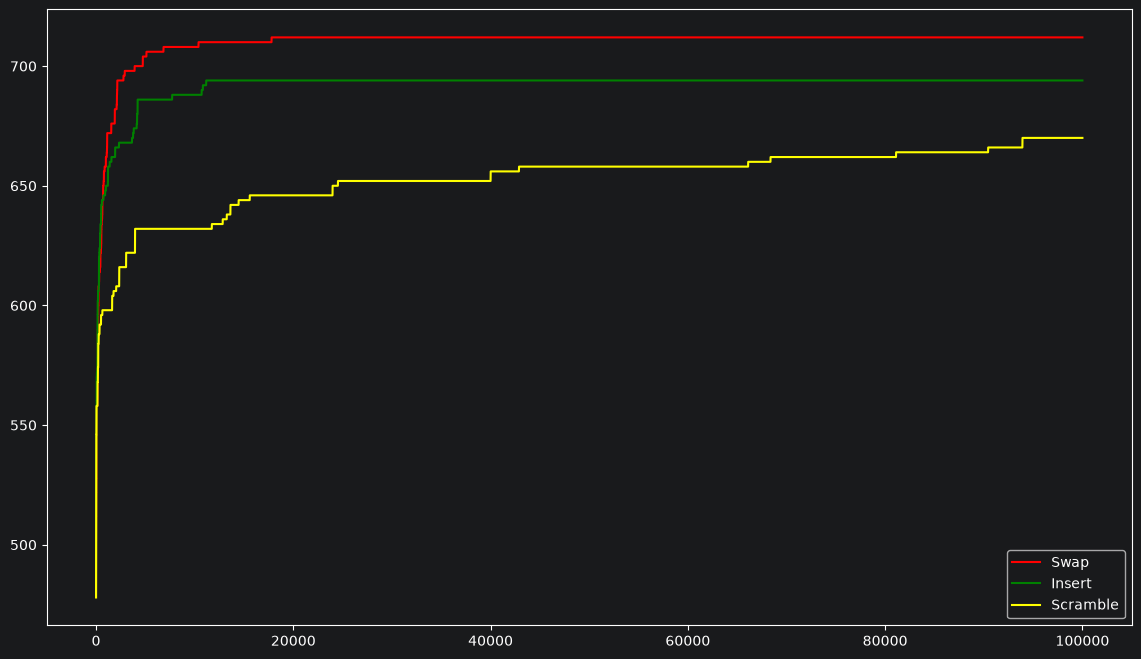

In [17]:
plt.figure(figsize=(14, 8))
plt.plot(
    range(len(swap_history)),
    list(accumulate(swap_history, max)),
    color='red'
)
plt.plot(
    range(len(insert_history)),
    list(accumulate(insert_history, max)),
    color='green'
)
plt.plot(
    range(len(scramble_history)),
    list(accumulate(scramble_history, max)),
    color='yellow'
)
plt.legend(["Swap", "Insert", "Scramble"], loc="lower right")